In [1]:
import os
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = "8"
import sys, json, random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from PIL import Image

SEED = 42
random.seed(SEED); np.random.seed(SEED)
PROJECT_ROOT = Path("/workspace/sic_final_project")
for d in ["data/processed", "data/splits"]:
    (PROJECT_ROOT / d).mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

LABEL_MAP = {"Cat": 0, "Dog": 1}
clean = pd.read_csv(PROJECT_ROOT / "data/metadata/metadata_clean.csv")
print(len(clean), clean["label"].value_counts().to_dict())

24964 {'Dog': 12486, 'Cat': 12478}


In [2]:
%%writefile -a /workspace/sic_final_project/src/data_processing.py


# ---------------- Phase 4: preprocessing and splitting ----------------
from sklearn.model_selection import StratifiedGroupKFold


def load_rgb(path):
    """Decode ANY supported image and standardise to 3-channel RGB (handles P, L, CMYK, RGBA)."""
    with Image.open(path) as img:
        img.load()
        return img.convert("RGB")


def resize_array(rgb_img, size):
    """Resize (stretching to a square) and return a uint8 array of shape (size, size, 3)."""
    return np.asarray(rgb_img.resize((size, size), Image.BILINEAR), dtype=np.uint8)


def _load_multi(path, sizes):
    rgb = load_rgb(path)
    return [resize_array(rgb, s) for s in sizes]


def build_caches(paths, sizes=(64, 128, 224), n_workers=8):
    """Decode each image ONCE and fill one uint8 array per size, in the order of `paths`."""
    arrays = [np.empty((len(paths), s, s, 3), dtype=np.uint8) for s in sizes]
    with ThreadPoolExecutor(max_workers=n_workers) as pool:
        for i, out in enumerate(pool.map(lambda p: _load_multi(p, sizes), paths)):
            for arr, a in zip(arrays, out):
                arr[i] = a
    return arrays


def make_splits(df, seed=42, n_folds=20, n_test_folds=3, n_val_folds=3):
    """70/15/15 split, stratified by label, near-duplicate groups kept together."""
    sgkf = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    fold = np.full(len(df), -1)
    for k, (_, idx) in enumerate(sgkf.split(df, df["label_id"], groups=df["group_id"])):
        fold[idx] = k
    split = np.where(fold < n_test_folds, "test",
            np.where(fold < n_test_folds + n_val_folds, "val", "train"))
    return pd.Series(split, index=df.index, name="split")

Appending to /workspace/sic_final_project/src/data_processing.py


/usr/local/lib/python3.10/dist-packages/PIL/TiffImagePlugin.py:900: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Built caches in 42s

64x64: shape (24964, 64, 64, 3) | dtype uint8 | 0.31 GB | min 0 max 255
128x128: shape (24964, 128, 128, 3) | dtype uint8 | 1.23 GB | min 0 max 255
224x224: shape (24964, 224, 224, 3) | dtype uint8 | 3.76 GB | min 0 max 255


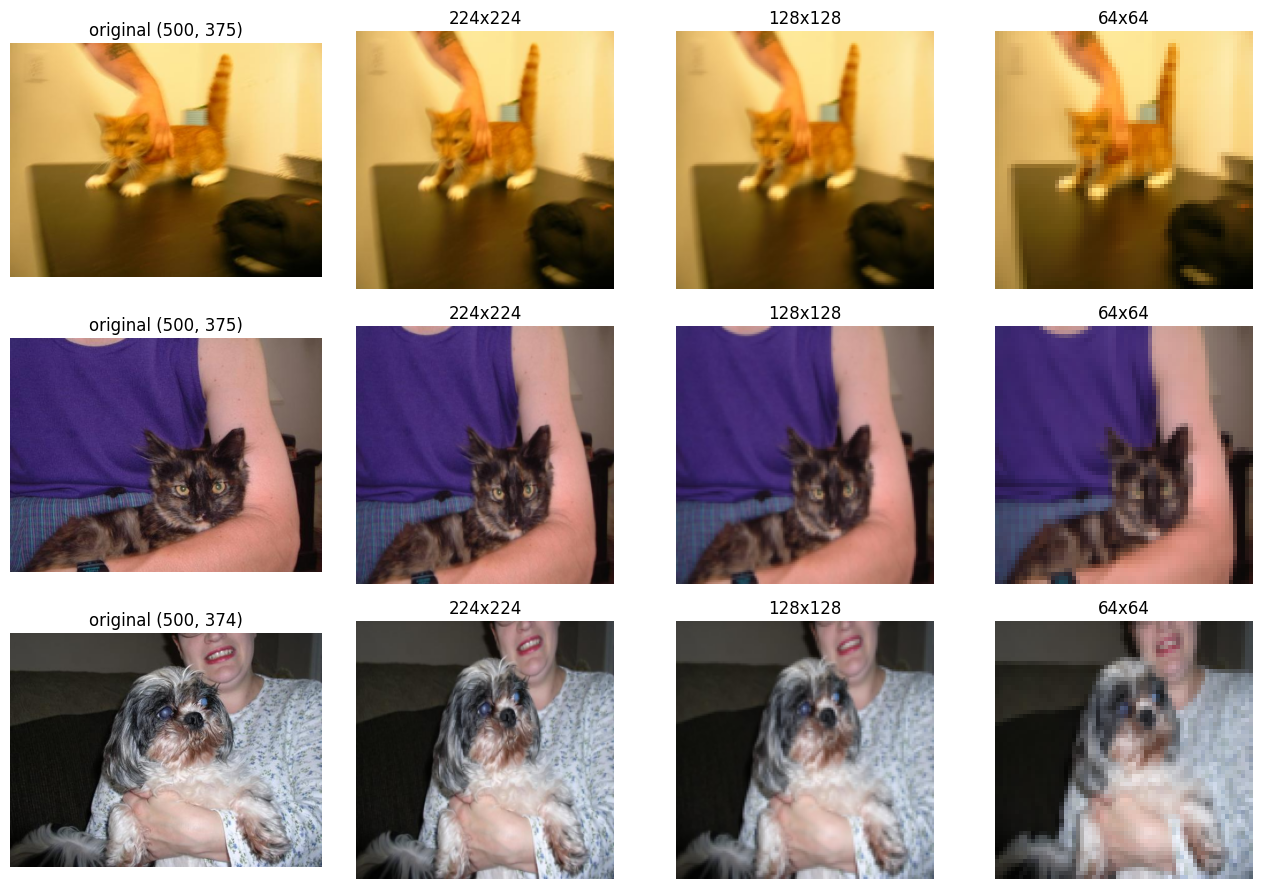

In [3]:
import importlib, data_processing
importlib.reload(data_processing)

t0 = time.time()
a64, a128, a224 = data_processing.build_caches(clean["path"].tolist(), sizes=(64, 128, 224))
print(f"Built caches in {time.time()-t0:.0f}s\n")
for name, arr in [("64", a64), ("128", a128), ("224", a224)]:
    print(f"{name}x{name}: shape {arr.shape} | dtype {arr.dtype} | {arr.nbytes/1e9:.2f} GB | min {arr.min()} max {arr.max()}")

# What resizing does to a few images
fig, ax = plt.subplots(3, 4, figsize=(13, 9))
for row, i in enumerate([0, 5000, 20000]):
    orig = data_processing.load_rgb(clean.loc[i, "path"])
    ax[row, 0].imshow(orig); ax[row, 0].set_title(f"original {orig.size}")
    for a, arr, n in zip(ax[row, 1:], (a224, a128, a64), (224, 128, 64)):
        a.imshow(arr[i]); a.set_title(f"{n}x{n}")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(PROJECT_ROOT / "results/figures/04_resize_demo.png", dpi=110); plt.show()

In [4]:
batch = a128[:8]
x = batch.astype(np.float32) / 255.0
print("before:", batch.dtype, batch.min(), batch.max(), "| after:", x.dtype, round(float(x.min()), 3), round(float(x.max()), 3))

clean["label_id"] = clean["label"].map(LABEL_MAP)
y = clean["label_id"].to_numpy(dtype=np.int64)
print("\nLabel encoding:", LABEL_MAP)
print(pd.Series(y).value_counts().sort_index().to_dict(), "| y shape:", y.shape)

before: uint8 0 255 | after: float32 0.0 1.0

Label encoding: {'Cat': 0, 'Dog': 1}
{0: 12478, 1: 12486} | y shape: (24964,)


In [5]:
clean["split"] = data_processing.make_splits(clean, seed=SEED)
clean["array_index"] = np.arange(len(clean))      # row number in the cached arrays

print(clean["split"].value_counts())
print("\nShare of the whole dataset:"); print(clean["split"].value_counts(normalize=True).round(4))
print("\nClass counts per split:"); print(pd.crosstab(clean["split"], clean["label"]))
print("\nClass proportions per split:"); print(pd.crosstab(clean["split"], clean["label"], normalize="index").round(4))

# Leakage guard: no file, no identical image, no near-duplicate group in more than one split
for col in ["path", "md5", "group_id"]:
    n = (clean.groupby(col)["split"].nunique() > 1).sum()
    print(f"{col:9s} present in more than one split: {n}")
    assert n == 0

# Q29: what a NAIVE random split would have done with the near-duplicate groups
from sklearn.model_selection import train_test_split
tr_idx, rest_idx = train_test_split(np.arange(len(clean)), test_size=0.30,
                                    stratify=clean["label_id"], random_state=SEED)
naive = np.array(["train"] * len(clean), dtype=object); naive[rest_idx] = "other"
g = pd.DataFrame({"group_id": clean["group_id"], "naive": naive})
group_size = g.groupby("group_id").size()
straddle = g.groupby("group_id")["naive"].nunique() > 1
print("\nNear-duplicate groups (size > 1):", int((group_size > 1).sum()))
print("...split across train and test by a NAIVE random split:", int(((group_size > 1) & straddle).sum()))

split
train    17479
test      3743
val       3742
Name: count, dtype: int64

Share of the whole dataset:
split
train    0.7002
test     0.1499
val      0.1499
Name: proportion, dtype: float64

Class counts per split:
label   Cat   Dog
split            
test   1870  1873
train  8738  8741
val    1870  1872

Class proportions per split:
label     Cat     Dog
split                
test   0.4996  0.5004
train  0.4999  0.5001
val    0.4997  0.5003
path      present in more than one split: 0
md5       present in more than one split: 0
group_id  present in more than one split: 0

Near-duplicate groups (size > 1): 6
...split across train and test by a NAIVE random split: 4


In [6]:
out = PROJECT_ROOT / "data/processed"
np.save(out / "images_64.npy", a64); np.save(out / "images_128.npy", a128)
np.save(out / "images_224.npy", a224); np.save(out / "labels.npy", y)

split_cols = ["array_index", "path", "label", "label_id", "group_id", "md5", "split"]
clean[split_cols].to_csv(PROJECT_ROOT / "data/splits/split_seed42.csv", index=False)

config = {
    "label_map": LABEL_MAP, "seed": SEED, "image_sizes": {"ml": 64, "cnn": 128, "pretrained": 224},
    "resize": "direct resize to square (stretch), PIL BILINEAR", "color": "RGB",
    "storage": "uint8; divide by 255 per batch",
    "imagenet_mean": [0.485, 0.456, 0.406], "imagenet_std": [0.229, 0.224, 0.225],
    "split": "StratifiedGroupKFold(20 folds): 3 test, 3 val, 14 train",
    "n_images": int(len(clean)),
}
(PROJECT_ROOT / "data/processed/preprocessing_config.json").write_text(json.dumps(config, indent=2))

# Cache rows must match the manifest: re-derive 5 random images from disk and compare
rng = np.random.default_rng(SEED)
for i in rng.choice(len(clean), 5, replace=False):
    ref = data_processing.resize_array(data_processing.load_rgb(clean.loc[i, "path"]), 128)
    assert np.array_equal(ref, a128[i])
print("Saved. Cache/manifest alignment check passed.")
!ls -lh /workspace/sic_final_project/data/processed

Saved. Cache/manifest alignment check passed.
total 5.0G
-rw-r--r-- 1 root root 1.2G Nov 16 06:20 images_128.npy
-rw-r--r-- 1 root root 3.5G Nov 16 06:20 images_224.npy
-rw-r--r-- 1 root root 293M Nov 16 06:20 images_64.npy
-rw-r--r-- 1 root root 196K Nov 16 06:20 labels.npy
-rw-r--r-- 1 root root  475 Nov 16 06:20 preprocessing_config.json
